# 조건문과 반복문

**이 노트북에서 할 일**

1. 회원일 때만 할인하고, 주문 금액 구간에 맞는 배송비를 하나 고릅니다.
2. 금액 목록을 `for`와 `while`로 하나씩 읽고, `continue`와 `break`로 건너뛰거나 멈춥니다.
3. 위치 번호를 1부터 세어 첫 주문을 빠뜨리는 장면을 보고, `enumerate()`로 고칩니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다.

1절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고릅니다.
이전 커널의 변수는 쓰지 않으므로 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

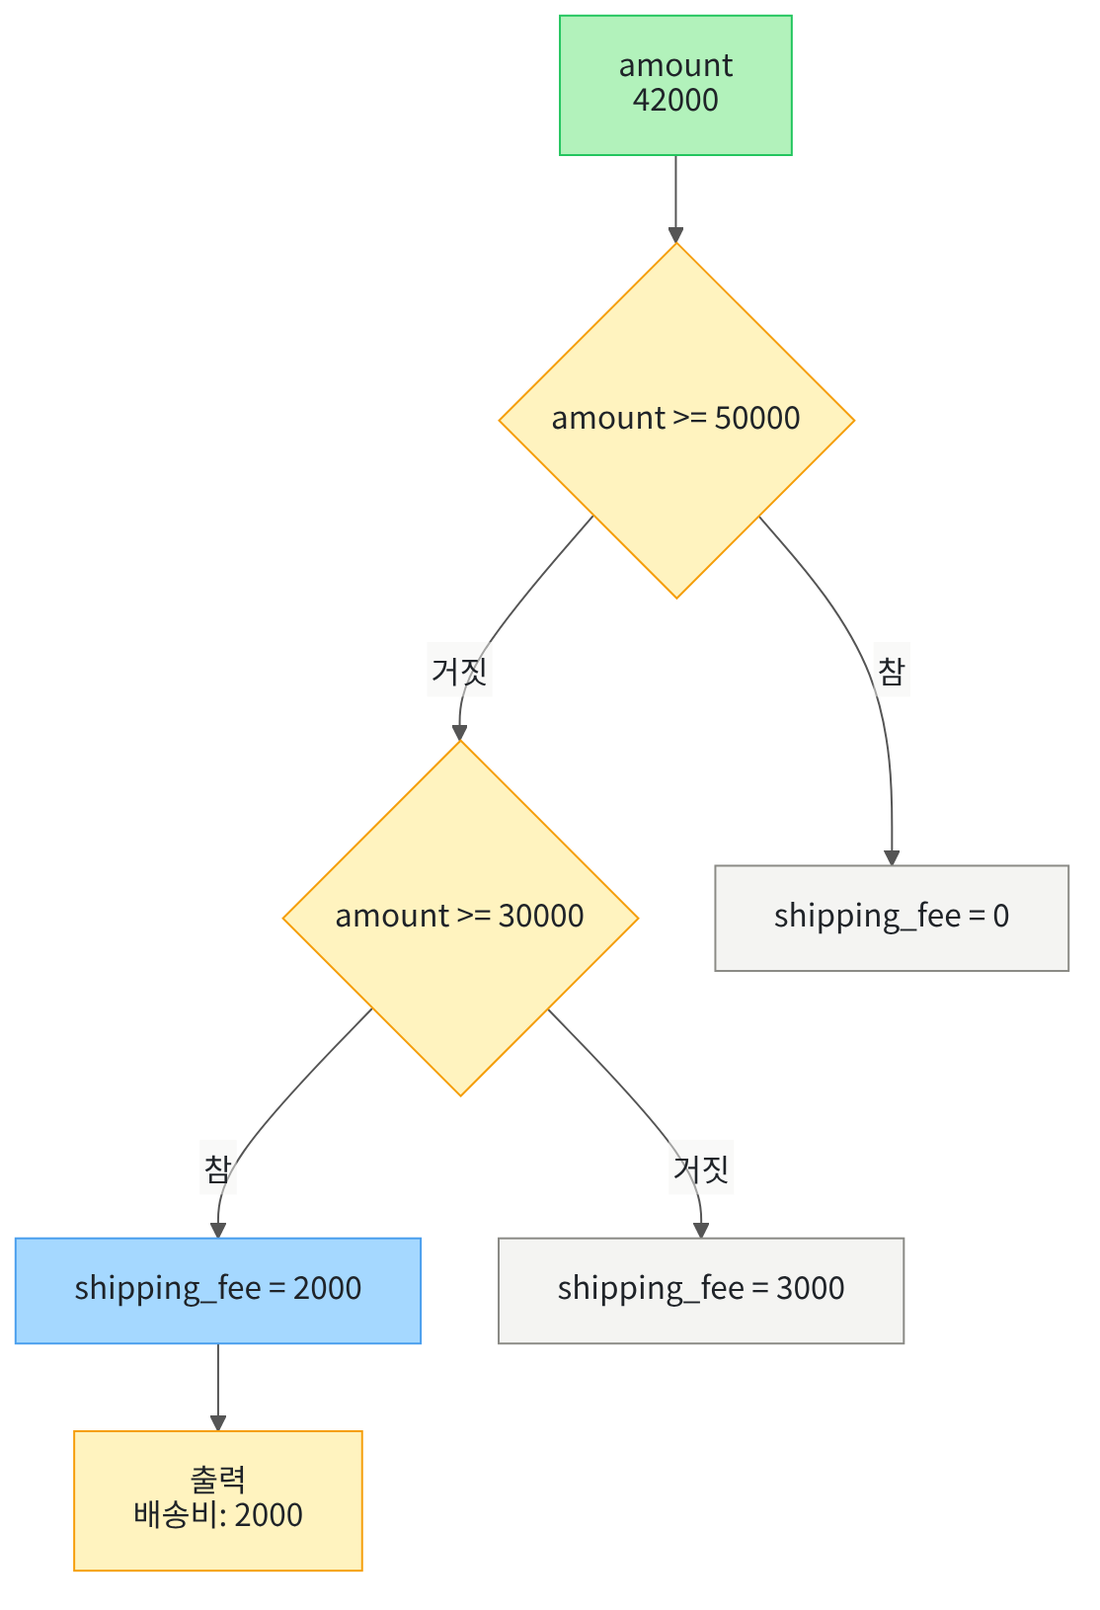

위에서 아래로 읽습니다. 노란 마름모는 조건 검사이고, 파란 상자는 실제로 실행한 줄입니다.
주문 금액 42000원은 첫 조건에서 거짓, 둘째 조건에서 참입니다. 그래서 배송비 2000원 줄 하나만 실행합니다.
회색 상자 두 줄은 이번에 실행하지 않은 줄입니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 준비 셀은 이 절에서 쓸 값을 새 커널에 저장합니다.
앞의 세 값은 1절에서 계산한 주문 한 건입니다. 주문 금액 78000.0, 할인율 0.1, 회원 여부 True를 그대로 씁니다.

주문 세 건의 금액은 Ch 1 1절처럼 대괄호 `[ ]`로 만든 목록에 담습니다.
1절의 주문 금액은 단가 39000.0이 실수라서 실수로 나왔습니다. 이 절의 금액은 1절 주의할 점대로 원 단위 정수로 적습니다.

In [1]:
# 1절에서 계산한 주문 한 건의 값을 새 커널에 다시 저장합니다
order_total = 78000.0
discount_rate = 0.1
is_member = True
# 이 절에서 차례로 처리할 주문 세 건의 금액입니다(원 단위 정수)
order_amounts = [18000, 42000, 65000]
print("1절 주문 금액:", order_total)
print("할인율:", discount_rate)
print("회원 여부:", is_member)
print("주문 세 건의 금액:", order_amounts)

1절 주문 금액: 78000.0
할인율: 0.1
회원 여부: True
주문 세 건의 금액: [18000, 42000, 65000]


**결과 읽기** — 1절 주문 금액 `78000.0`, 할인율 `0.1`, 회원 여부 `True`가 저장됐습니다.
주문 세 건의 금액은 `[18000, 42000, 65000]`입니다. 소수점이 없는 정수 세 개입니다.

## 2. 회원일 때만 할인하기

1절에서는 회원 여부를 따지지 않고 할인액을 계산했습니다. 이번에는 회원일 때만 할인합니다.
조건문(conditional statement)은 조건이 참인지 거짓인지에 따라 실행할 줄을 고르는 문장입니다.
계산대에서 회원 카드를 내면 할인하고, 카드가 없으면 정가를 받는 모습과 같습니다.

Ch 1 3절에서 여러 줄 `if`와 `else`를 써 보았습니다. 조건 뒤에는 콜론 `:`을 붙이고, 그 조건에 속한 줄은 들여 씁니다.
조건 자리에는 불리언 변수 `is_member`를 그대로 둘 수 있습니다. 값이 `True`이면 `if` 아래 줄을, `False`이면 `else` 아래 줄을 실행합니다.

In [2]:
# 회원이면 할인액을 계산하고, 회원이 아니면 할인액을 0.0으로 둡니다
if is_member:
    discount = order_total * discount_rate
else:
    discount = 0.0
# 할인액이 정해진 뒤에 결제 금액을 계산합니다
payment = order_total - discount
print("회원 여부:", is_member)
print("할인액:", discount)
print("결제 금액:", payment)

회원 여부: True
할인액: 7800.0
결제 금액: 70200.0


**결과 읽기** — 회원 여부가 `True`라서 `if` 아래 줄을 실행했습니다. 할인액은 `7800.0`, 결제 금액은 `70200.0`입니다.
1절에서 계산한 결과와 같습니다. 이번에는 `else` 아래 줄이 실행되지 않았습니다.

회원 여부 하나만 `False`로 바꿔 같은 조건문을 다시 실행합니다. 주문 금액과 할인율은 그대로 둡니다.
실행 전에 예상합니다. 이번에는 `else` 아래 줄이 실행되어 할인액 0.0, 결제 금액 78000.0이 나올 것입니다.

In [3]:
# 회원 여부만 False로 바꾸고 같은 조건문을 다시 실행합니다
is_member = False
if is_member:
    discount = order_total * discount_rate
else:
    discount = 0.0
payment = order_total - discount
print("회원 여부:", is_member)
print("할인액:", discount)
print("결제 금액:", payment)

회원 여부: False
할인액: 0.0
결제 금액: 78000.0


**결과 읽기** — 할인액 `0.0`, 결제 금액 `78000.0`으로 예상과 같습니다. 회원 여부가 `False`라서 `else` 아래 줄을 실행했습니다.
바꾼 값은 회원 여부 하나뿐입니다. 그래서 결제 금액이 달라진 원인은 회원 여부입니다.

## 3. 금액 구간으로 배송비 고르기

배송비 규칙은 세 구간입니다. 50000원 이상은 무료, 30000원 이상은 2000원, 그보다 작으면 3000원입니다.
갈림길이 셋 이상이면 `if`와 `else` 사이에 `elif`를 넣습니다. 조건 줄 `elif`는 앞 조건이 거짓일 때만 검사합니다.

비교 연산자 `>=`는 왼쪽 값이 오른쪽 값보다 크거나 같은지 검사합니다. 결과는 Ch 1의 `==`처럼 `True`나 `False`입니다.
조건은 위에서부터 차례로 검사합니다. 처음 참이 된 곳의 줄 하나만 실행하고 나머지는 건너뜁니다.

실행 전에 예상합니다. 42000원은 첫 조건에서 거짓, 둘째 조건에서 참이라 배송비는 2000원일 것입니다.

In [4]:
# 주문 금액 42000원이 세 구간 가운데 어디에 드는지 골라 배송비를 정합니다
free_shipping_minimum = 50000
reduced_fee_minimum = 30000
amount = 42000
# 위에서부터 검사해 처음 참이 된 곳의 줄 하나만 실행합니다
if amount >= free_shipping_minimum:
    shipping_fee = 0
elif amount >= reduced_fee_minimum:
    shipping_fee = 2000
else:
    shipping_fee = 3000
print("주문 금액:", amount)
print("배송비:", shipping_fee)

주문 금액: 42000
배송비: 2000


**결과 읽기** — 주문 금액 `42000`의 배송비는 `2000`으로 예상과 같습니다.
첫 조건 `amount >= free_shipping_minimum`은 거짓이라 그 아래 줄을 건너뛰었습니다. 둘째 조건이 참이라 배송비를 2000으로 정하는 줄을 실행했습니다.
둘째 조건이 참이 된 뒤에는 `else` 아래 줄을 실행하지 않습니다.

## 4. 여러 금액의 배송비를 for로 고르기

반복(iteration)은 같은 규칙을 여러 값에 차례로 적용하는 일입니다. Ch 1 1절의 반복문 `for`는 목록의 값마다 들여 쓴 줄을 한 번씩 실행했습니다.
이번에는 `for` 안에 앞 셀의 조건문을 그대로 넣습니다. 조건문은 반복문보다 한 단계 더 들여 씁니다.

금액 다섯 개에는 경계값 49999원과 50000원을 넣었습니다. 기호 `>=`는 같은 값도 참으로 봅니다.
실행 전에 예상합니다. 49999원은 2000원, 50000원은 0원일 것입니다.

In [5]:
# 경계값 49999원과 50000원을 넣은 금액 다섯 개의 배송비를 차례로 고릅니다
test_amounts = [18000, 42000, 49999, 50000, 65000]
for amount in test_amounts:
    # 반복할 때마다 amount에 새 금액이 담기고, 조건을 처음부터 검사합니다
    if amount >= free_shipping_minimum:
        shipping_fee = 0
    elif amount >= reduced_fee_minimum:
        shipping_fee = 2000
    else:
        shipping_fee = 3000
    print(f"{amount}원 → 배송비 {shipping_fee}원")

18000원 → 배송비 3000원
42000원 → 배송비 2000원
49999원 → 배송비 2000원
50000원 → 배송비 0원
65000원 → 배송비 0원


**결과 읽기** — 다섯 줄이 출력됐습니다. 경계값 두 줄은 `49999원 → 배송비 2000원`과 `50000원 → 배송비 0원`으로 예상과 같습니다.
첫 줄 `18000원 → 배송비 3000원`은 두 조건이 모두 거짓이라 `else` 아래 줄을 실행한 결과입니다.
50000원보다 1원 적은 금액과 같은 금액의 배송비가 2000원 차이 납니다. 경계값을 꼭 넣어 확인하는 이유입니다.

## 5. range()로 번호 만들기

내장 함수 `range()`는 차례로 늘어나는 번호를 만듭니다. 반복문 `for`와 함께 쓰면 번호마다 한 번씩 반복합니다.

괄호 안에 숫자 하나를 넣으면 0부터 그 숫자 바로 앞까지 만듭니다. 숫자 두 개를 넣으면 앞 숫자부터 뒤 숫자 바로 앞까지 만듭니다.
두 경우 모두 끝 숫자는 들어가지 않습니다.

실행 전에 예상합니다. 함수 호출 `range(3)`은 0, 1, 2를, `range(1, 3)`은 1, 2를 만들 것입니다.

In [6]:
# range(3)이 만드는 번호를 차례로 출력합니다
for number in range(3):
    print("range(3)의 번호:", number)
# 숫자를 두 개 넣으면 시작 번호를 정할 수 있습니다
for number in range(1, 3):
    print("range(1, 3)의 번호:", number)

range(3)의 번호: 0
range(3)의 번호: 1
range(3)의 번호: 2
range(1, 3)의 번호: 1
range(1, 3)의 번호: 2


**결과 읽기** — 첫 반복은 `range(3)의 번호: 0`부터 `range(3)의 번호: 2`까지 세 줄입니다. 끝 숫자 3은 나오지 않았습니다.
둘째 반복은 `range(1, 3)의 번호: 1`과 `range(1, 3)의 번호: 2` 두 줄입니다. 시작 번호가 1이라서 0이 빠졌습니다.

## 6. while로 목록 끝까지 읽기

반복문 `while`은 조건이 참인 동안 들여 쓴 줄을 되풀이합니다. 줄 선 손님이 남아 있는 동안 계산을 계속하는 모습과 같습니다.
기호 `<`는 왼쪽 값이 오른쪽 값보다 작은지 검사합니다. 함수 `len()`은 Ch 1에서 쓴 대로 목록의 항목 수를 반환합니다.

목록의 위치 번호는 Ch 1 3절에서 본 대로 0부터 셉니다. 읽는 식 `order_amounts[index]`는 위치 번호 `index`의 값을 꺼냅니다.
반복할 때마다 번호를 1씩 늘립니다. 번호를 늘리지 않으면 조건이 계속 참이라서 반복이 끝나지 않습니다.
실행 전에 예상합니다. 번호가 3이 되면 조건이 거짓이 되어 반복이 끝날 것입니다.

In [7]:
# 위치 번호 0부터 목록 길이 바로 앞까지 while로 주문 금액을 읽습니다
index = 0
while index < len(order_amounts):
    amount = order_amounts[index]
    print("위치", index, "주문 금액:", amount)
    # 번호를 늘리지 않으면 조건이 계속 참이라 반복이 끝나지 않습니다
    index = index + 1
print("반복이 끝난 뒤 위치 번호:", index)

위치 0 주문 금액: 18000
위치 1 주문 금액: 42000
위치 2 주문 금액: 65000
반복이 끝난 뒤 위치 번호: 3


**결과 읽기** — 위치 0부터 2까지 세 줄이 출력됐습니다. 첫 줄은 `위치 0 주문 금액: 18000`, 마지막 줄은 `위치 2 주문 금액: 65000`입니다.
반복이 끝난 뒤 위치 번호는 `3`입니다. 3은 목록의 항목 수와 같아서 조건이 거짓이 됐고, 반복이 멈췄습니다.

## 7. continue로 건너뛰고 break로 멈추기

주문 기록에 특별한 표시가 섞여 있다고 가정합니다. 금액 -1은 취소된 주문이고, 0은 여기서 처리를 멈추라는 표시입니다.
예약어 `continue`는 이번 차례의 남은 줄을 건너뛰고 다음 차례로 넘어갑니다. 예약어 `break`는 반복 전체를 그 자리에서 끝냅니다.
택배 상자를 차례로 포장하다가 취소된 상자는 옆으로 넘깁니다. 마감 팻말이 나오면 그 자리에서 일을 멈춥니다.

이 셀은 번호를 늘리는 줄을 `continue`보다 앞에 둡니다. 뒤에 두면 -1에서 번호가 늘지 않아 같은 값을 계속 읽습니다.
그 장면은 반복이 끝나지 않으므로 이번에 실행하지 않았습니다.
실행 전에 예상합니다. 18000과 42000만 처리하고, 0 뒤의 65000은 읽지 않을 것입니다.

In [8]:
# -1은 건너뛰고 0을 만나면 멈추면서 금액을 하나씩 읽습니다
amounts_with_stop = [18000, -1, 42000, 0, 65000]
index = 0
while index < len(amounts_with_stop):
    amount = amounts_with_stop[index]
    # continue보다 먼저 번호를 늘려야 다음 차례로 넘어갑니다
    index = index + 1
    print("읽은 값:", amount)
    if amount < 0:
        continue
    if amount == 0:
        break
    print("  처리한 금액:", amount)
print("반복이 끝난 뒤 위치 번호:", index)

읽은 값: 18000
  처리한 금액: 18000
읽은 값: -1
읽은 값: 42000
  처리한 금액: 42000
읽은 값: 0
반복이 끝난 뒤 위치 번호: 4


**결과 읽기** — 읽은 값은 `18000`, `-1`, `42000`, `0` 네 개입니다. 처리한 금액은 `처리한 금액: 18000`과 `처리한 금액: 42000` 두 줄뿐입니다.
-1을 읽은 차례에는 `continue`를 만나 처리 줄을 건너뛰었습니다. 0을 읽은 차례에는 `break`를 만나 반복이 끝났습니다.
반복이 끝난 뒤 위치 번호는 `4`입니다. 위치 4에 있는 65000은 읽지 않았습니다.

## 8. 값 바꿔 보기 — 무료 배송 기준 낮추기

주문 세 건 가운데 무료 배송 주문이 몇 건인지 셉니다. 조건이 참일 때마다 개수 변수에 1을 더합니다.
Ch 1 1절에서 번호를 1씩 늘린 `number = number + 1`과 같은 모양입니다.
먼저 3번 소제목의 기준 50000원으로 셉니다. 65000원 한 건만 기준 이상이라 1건일 것입니다.

In [9]:
# 주문 세 건 가운데 무료 배송 기준 이상인 주문 수를 셉니다
free_count = 0
for amount in order_amounts:
    if amount >= free_shipping_minimum:
        free_count = free_count + 1
print("무료 배송 기준:", free_shipping_minimum)
print("무료 배송 주문 수:", free_count)

무료 배송 기준: 50000
무료 배송 주문 수: 1


**결과 읽기** — 무료 배송 기준 `50000`에서 무료 배송 주문 수는 `1`입니다. 세 금액 가운데 65000원만 기준 이상입니다.

이제 변수 `free_shipping_minimum` 하나만 40000으로 바꿉니다. 주문 금액과 세는 방법은 그대로 둡니다.
실행 전에 예상합니다. 42000원도 기준 이상이 되어 2건일 것입니다.

In [10]:
# 무료 배송 기준 하나만 40000원으로 낮추고 같은 방법으로 다시 셉니다
free_shipping_minimum = 40000
free_count = 0
for amount in order_amounts:
    if amount >= free_shipping_minimum:
        free_count = free_count + 1
print("무료 배송 기준:", free_shipping_minimum)
print("무료 배송 주문 수:", free_count)

무료 배송 기준: 40000
무료 배송 주문 수: 2


**결과 읽기** — 기준 `40000`에서 무료 배송 주문 수는 `2`로 예상과 같습니다. 새로 무료 배송이 된 주문은 42000원입니다.
바꾼 값은 기준 하나뿐입니다. 그래서 1건이 2건으로 늘어난 원인은 기준을 낮춘 것입니다.

## 9. Before — 위치 번호를 1부터 세기

Ch 1 1절에서 과정 지도에 번호를 붙일 때는 1부터 셌습니다. 사람은 첫째 주문도 보통 1번 주문이라고 부릅니다.
그 습관대로 `range(1, order_count)`로 위치 번호를 만들어 주문을 읽는다고 해 봅니다.
확인한 주문 수가 목록의 항목 수와 같은지도 비교합니다. 실행 전에 세 건을 모두 읽을지 예상해 봅니다.

In [11]:
# 위치 번호를 1부터 세어 주문 금액을 읽고 건수와 합계를 셉니다
order_count = len(order_amounts)
checked_count = 0
checked_total = 0
for index in range(1, order_count):
    amount = order_amounts[index]
    print("위치", index, "주문 금액:", amount)
    checked_count = checked_count + 1
    checked_total = checked_total + amount
# 확인한 주문 수가 목록의 항목 수와 같은지 비교합니다
is_all_checked = checked_count == order_count
print("확인한 주문 수:", checked_count)
print("확인한 금액 합계:", checked_total)
print("항목 수와 같은가:", is_all_checked)

위치 1 주문 금액: 42000
위치 2 주문 금액: 65000
확인한 주문 수: 2
확인한 금액 합계: 107000
항목 수와 같은가: False


**결과 읽기** — 출력된 주문은 `위치 1 주문 금액: 42000`과 `위치 2 주문 금액: 65000` 두 줄입니다.
확인한 주문 수는 `2`, 합계는 `107000`입니다. 항목 수와 비교한 결과는 `False`입니다.

위치 0의 18000원을 읽지 않았습니다. 목록의 위치 번호는 0부터인데, 이 셀의 번호는 1부터 시작했기 때문입니다.
오류 메시지는 나오지 않았습니다. 1절의 222처럼 실행이 멈추지 않아도 결과는 틀릴 수 있습니다.

### 원리 더 알아보기 — 끝을 넘겨 읽으면 나오는 오류

1부터 세는 습관으로 끝 숫자까지 하나 늘리면 어떻게 될까요? 목록에 없는 위치 3까지 읽게 됩니다.
없는 위치를 읽으면 오류가 나고 셀 실행이 멈춥니다. 아래 셀은 멈추지 않고 오류 이름만 보려고 `try`와 `except`를 씁니다.
이 문법은 5절 파일과 예외에서 배우므로 지금은 출력만 읽습니다.

In [12]:
# 원리 더 알아보기: 끝 숫자를 하나 늘려 없는 위치 3까지 읽어 봅니다
try:
    for index in range(1, order_count + 1):
        amount = order_amounts[index]
        print("위치", index, "주문 금액:", amount)
except IndexError as error:
    print("오류 이름:", type(error).__name__)
    print("오류 메시지:", error)

위치 1 주문 금액: 42000
위치 2 주문 금액: 65000
오류 이름: IndexError
오류 메시지: list index out of range


**결과 읽기** — 위치 1과 2를 읽은 뒤 오류 이름 `IndexError`가 나왔습니다. 오류 메시지 `list index out of range`는 목록 범위를 벗어난 위치라는 뜻입니다.
Before 셀은 틀린 결과를 조용히 냈지만, 이번에는 오류로 멈췄습니다.

## 10. After — enumerate()로 위치 번호와 값을 함께 받기

내장 함수 `enumerate()`는 목록의 항목마다 위치 번호를 붙여 줍니다. 번호는 0부터 시작합니다.
반복문 머리에 이름 두 개를 쉼표로 적으면 위치 번호와 값이 차례로 담깁니다. 예를 들어 `for index, amount in enumerate(order_amounts):`처럼 씁니다.
번호를 직접 계산하지 않으므로 시작 번호를 잘못 적을 일이 없습니다.

Before 셀과 달라진 곳은 반복문 머리 한 줄입니다. 값도 함께 받으므로 위치 번호로 값을 꺼내는 줄은 뺐습니다.
실행 전에 예상합니다. 위치 0부터 2까지 세 건을 읽고, 비교 결과는 `True`일 것입니다.

In [13]:
# enumerate()가 붙여 주는 위치 번호와 금액을 함께 받아 건수와 합계를 셉니다
checked_count = 0
checked_total = 0
for index, amount in enumerate(order_amounts):
    print("위치", index, "주문 금액:", amount)
    checked_count = checked_count + 1
    checked_total = checked_total + amount
is_all_checked = checked_count == order_count
print("확인한 주문 수:", checked_count)
print("확인한 금액 합계:", checked_total)
print("항목 수와 같은가:", is_all_checked)
# 세 건을 모두 확인하지 못했으면 이 줄에서 실행을 멈춥니다
assert is_all_checked

위치 0 주문 금액: 18000
위치 1 주문 금액: 42000
위치 2 주문 금액: 65000
확인한 주문 수: 3
확인한 금액 합계: 125000
항목 수와 같은가: True


**결과 읽기** — 첫 줄은 `위치 0 주문 금액: 18000`이고 위치 2까지 세 줄이 출력됐습니다.
확인한 주문 수는 `3`, 합계는 `125000`입니다. 비교 결과는 `True`이고, 검사 줄 `assert`에서도 멈추지 않았습니다.

Before 셀의 2건과 107000원이 3건과 125000원으로 바뀌었습니다. 빠졌던 18000원이 들어간 차이입니다.
시작 번호를 빼고 `range(order_count)`로 고쳐도 0부터 셉니다. 이 방법은 이번에 실행하지 않았습니다.

## 정리

- 조건문은 조건이 참인지 거짓인지에 따라 실행할 줄을 고릅니다. 회원일 때만 할인해 결제 금액 70200.0을 얻었습니다.
- 조건 줄 `if`·`elif`·`else`는 위에서부터 검사해 처음 참이 된 곳 하나만 실행합니다. 기호 `>=`는 같은 값도 참이라서 50000원은 무료 배송입니다.
- 반복문 `for`는 목록의 값마다, `while`은 조건이 참인 동안 반복합니다. 예약어 `continue`는 이번 차례를 건너뛰고, `break`는 반복을 끝냅니다.
- 목록의 위치 번호는 0부터입니다. 번호를 1부터 세면 첫 주문을 빠뜨리므로 `enumerate()`로 번호와 값을 함께 받습니다.

다음 절에서는 목록을 더 자세히 다루고, 튜플·딕셔너리·집합에 여러 값을 목적에 맞게 저장합니다.